### Markdown: Project objective


## Project
Customer Lifetime Value and Churn Intelligence System

## Objective
Estimate the financial viability of retention campaigns by combining
customer churn risk from Notebook 07 with customer lifetime value from
Notebook 08.

## Business questions
1. Which high-risk customers should be considered for retention offers?
2. How much might a retention campaign cost?
3. What would happen under conservative, base, and optimistic scenarios?
4. What are the estimated benefits, net returns, and ROI?
5. Which assumptions need to be tested using real campaign data?

## Important limitation
The Telco dataset does not contain randomized retention-campaign
assignments or observed campaign outcomes. Results are scenario-based
estimates, not causal uplift estimates or guaranteed financial returns.

### Import libraries and configure paths

In [8]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Run this notebook from the project's notebooks/ directory.
project_dir = Path("..")

retention_file = (
    project_dir / "reports" / "retention"
    / "customer_retention_priority.csv"
)

clv_file = (
    project_dir / "reports" / "clv"
    / "customer_clv_scenarios.csv"
)

output_dir = project_dir / "reports" / "roi"
output_dir.mkdir(parents=True, exist_ok=True)

print("Retention file:", retention_file)
print("CLV file:", clv_file)
print("Output directory:", output_dir)

Retention file: ..\reports\retention\customer_retention_priority.csv
CLV file: ..\reports\clv\customer_clv_scenarios.csv
Output directory: ..\reports\roi


### Load the Notebook 7 and Notebook 8 outputs

In [9]:
if not retention_file.exists():
    raise FileNotFoundError(
        f"{retention_file} not found. Run Notebook 07 first."
    )

if not clv_file.exists():
    raise FileNotFoundError(
        f"{clv_file} not found. Run Notebook 08 first."
    )

retention_df = pd.read_csv(retention_file)
clv_df = pd.read_csv(clv_file)

print("Retention data shape:", retention_df.shape)
print("CLV data shape:", clv_df.shape)

print("\nRetention columns:")
print(retention_df.columns.tolist())

print("\nCLV columns:")
print(clv_df.columns.tolist())

Retention data shape: (7043, 12)
CLV data shape: (7043, 20)

Retention columns:
['customer_id', 'predicted_churn_probability', 'actual_churn', 'tenure_months', 'monthly_charges', 'contract_type', 'internet_service', 'churn_risk_band', 'retention_priority', 'recommended_retention_action', 'shap_context_file', 'historical_survival_probability_at_tenure']

CLV columns:
['customer_id', 'predicted_churn_probability', 'actual_churn', 'tenure_months', 'monthly_charges', 'contract_type', 'internet_service', 'churn_risk_band', 'retention_priority', 'recommended_retention_action', 'shap_context_file', 'historical_survival_probability_at_tenure', 'monthly_revenue', 'estimated_monthly_contribution', 'retention_factor_assumption', 'estimated_clv_base', 'estimated_clv_conservative', 'estimated_clv_optimistic', 'clv_scenario_band', 'value_risk_segment']


### Standardize column names

In [10]:
def standardize_columns(df):
    df = df.copy()
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    return df


retention_df = standardize_columns(retention_df)
clv_df = standardize_columns(clv_df)

print("Standardized retention columns:")
print(retention_df.columns.tolist())

print("\nStandardized CLV columns:")
print(clv_df.columns.tolist())

Standardized retention columns:
['customer_id', 'predicted_churn_probability', 'actual_churn', 'tenure_months', 'monthly_charges', 'contract_type', 'internet_service', 'churn_risk_band', 'retention_priority', 'recommended_retention_action', 'shap_context_file', 'historical_survival_probability_at_tenure']

Standardized CLV columns:
['customer_id', 'predicted_churn_probability', 'actual_churn', 'tenure_months', 'monthly_charges', 'contract_type', 'internet_service', 'churn_risk_band', 'retention_priority', 'recommended_retention_action', 'shap_context_file', 'historical_survival_probability_at_tenure', 'monthly_revenue', 'estimated_monthly_contribution', 'retention_factor_assumption', 'estimated_clv_base', 'estimated_clv_conservative', 'estimated_clv_optimistic', 'clv_scenario_band', 'value_risk_segment']


### Merge retention risk and CLV data

In [11]:
# Try to identify the customer identifier in both datasets.
id_candidates = [
    "customerid",
    "customer_id",
    "customer",
    "id"
]

retention_id = next(
    (c for c in id_candidates if c in retention_df.columns),
    None
)

clv_id = next(
    (c for c in id_candidates if c in clv_df.columns),
    None
)

if retention_id and clv_id:
    if retention_id != clv_id:
        clv_df = clv_df.rename(columns={clv_id: retention_id})

    customer_df = retention_df.merge(
        clv_df,
        on=retention_id,
        how="inner",
        suffixes=("_retention", "_clv"),
        validate="one_to_one"
    )

    print("Merged using customer ID:", retention_id)

else:
    raise ValueError(
        "A matching customer ID column is required in both files. "
        "Check the column names printed in Cell 3 before proceeding."
    )

if customer_df.empty:
    raise ValueError(
        "The merge returned zero customers. Check the customer IDs "
        "and ensure both notebooks used the same dataset."
    )

print("Merged customer data shape:", customer_df.shape)
print("Unique customers:", customer_df[retention_id].nunique())

customer_df.head()

Merged using customer ID: customer_id
Merged customer data shape: (7043, 31)
Unique customers: 7043


,customer_id,predicted_churn_probability_retention,actual_churn_retention,tenure_months_retention,monthly_charges_retention,contract_type_retention,internet_service_retention,churn_risk_band_retention,retention_priority_retention,recommended_retention_action_retention,...,shap_context_file_clv,historical_survival_probability_at_tenure_clv,monthly_revenue,estimated_monthly_contribution,retention_factor_assumption,estimated_clv_base,estimated_clv_conservative,estimated_clv_optimistic,clv_scenario_band,value_risk_segment
0,6618-RYATB,0.905174,1,1,79.55,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,...,shap_feature_importance.csv,0.945961,79.55,23.865,0.094826,26.077001,23.628713,29.275949,Lower CLV,Lower value / high risk
1,1448-PWKYE,0.905174,1,1,80.00,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,...,shap_feature_importance.csv,0.945961,80.00,24.000,0.094826,26.224514,23.762376,29.441557,Lower CLV,Lower value / high risk
2,2514-GINMM,0.905174,1,1,79.50,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,...,shap_feature_importance.csv,0.945961,79.50,23.850,0.094826,26.060610,23.613861,29.257548,Lower CLV,Lower value / high risk
3,9019-QVLZD,0.905174,1,1,79.55,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,...,shap_feature_importance.csv,0.945961,79.55,23.865,0.094826,26.077001,23.628713,29.275949,Lower CLV,Lower value / high risk
4,9300-RENDD,0.905174,1,1,79.95,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...,...,shap_feature_importance.csv,0.945961,79.95,23.985,0.094826,26.208123,23.747525,29.423156,Lower CLV,Lower value / high risk


### Identify churn probability and CLV columns

In [13]:

# Identify columns for churn risk and customer lifetime value

def find_column(df, candidates, description):
    # Match column names without case sensitivity
    column_map = {col.lower(): col for col in df.columns}

    for candidate in candidates:
        if candidate.lower() in column_map:
            return column_map[candidate.lower()]

    raise ValueError(
        f"Could not identify {description}.\n"
        f"Available columns: {df.columns.tolist()}\n"
        f"Expected one of: {candidates}"
    )


# Notebook 07: Churn risk probability
risk_col = find_column(
    customer_df,
    [
        "predicted_churn_probability_retention",
        "predicted_churn_probability",
        "churn_probability",
        "predicted_churn_prob",
        "churn_risk_probability"
    ],
    "predicted churn probability"
)

# Notebook 08: Base-scenario customer lifetime value
clv_col = find_column(
    customer_df,
    [
        "estimated_clv_base",
        "customer_lifetime_value",
        "predicted_clv",
        "clv"
    ],
    "base-scenario customer lifetime value"
)

print("Churn probability column:", risk_col)
print("CLV column:", clv_col)


Churn probability column: predicted_churn_probability_retention
CLV column: estimated_clv_base


### Clean and validate the financial inputs

In [15]:
customer_df[risk_col] = pd.to_numeric(
    customer_df[risk_col], errors="coerce"
)

customer_df[clv_col] = pd.to_numeric(
    customer_df[clv_col], errors="coerce"
)

customer_df = customer_df.dropna(
    subset=[retention_id, risk_col, clv_col]
).copy()

# Churn probabilities must be between 0 and 1.
customer_df = customer_df[
    customer_df[risk_col].between(0, 1)
].copy()

# Use non-negative CLV for this campaign-benefit calculation.
customer_df[clv_col] = customer_df[clv_col].clip(lower=0)

if customer_df.empty:
    raise ValueError(
        "No valid customer records remain after validation."
    )

print("Valid customers:", len(customer_df))
print("Missing churn probabilities:", customer_df[risk_col].isna().sum())
print("Missing CLV values:", customer_df[clv_col].isna().sum())

print("\nChurn probability summary:")
print(customer_df[risk_col].describe())

print("\nBase CLV summary:")
print(customer_df[clv_col].describe())

Valid customers: 7043
Missing churn probabilities: 0
Missing CLV values: 0

Churn probability summary:
count    7043.000000
mean        0.265801
std         0.237757
min         0.000063
25%         0.045201
50%         0.220490
75%         0.423742
max         0.905174
Name: predicted_churn_probability_retention, dtype: float64

Base CLV summary:
count    7043.000000
mean      125.458623
std       126.158723
min         8.408046
25%        47.062855
50%        86.396279
75%       132.572800
max       708.536022
Name: estimated_clv_base, dtype: float64


### Define campaign assumptions

In [16]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# Cell 8: Define and validate campaign assumptions
# --------------------------------------------------

# Confirm that the required columns exist.
required_columns = [risk_col, clv_col]

missing_columns = [
    col for col in required_columns
    if col not in customer_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert selected columns to numeric values.
customer_df[risk_col] = pd.to_numeric(
    customer_df[risk_col], errors="coerce"
)

customer_df[clv_col] = pd.to_numeric(
    customer_df[clv_col], errors="coerce"
)

# Illustrative campaign assumptions.
# These are not experimentally measured outcomes.
HIGH_RISK_THRESHOLD = 0.60
COST_PER_CONTACT = 10.0

RETENTION_LIFT_SCENARIOS = {
    "Conservative": 0.03,
    "Base": 0.07,
    "Optimistic": 0.12
}

# Set True only if estimated_clv_base represents
# future contribution value rather than revenue.
CLV_IS_CONTRIBUTION_VALUE = True

# Validate the data before campaign calculations.
if customer_df[risk_col].isna().any():
    raise ValueError(
        f"{risk_col} contains missing or non-numeric values."
    )

if not customer_df[risk_col].between(0, 1).all():
    raise ValueError(
        "Churn probabilities must be between 0 and 1."
    )

if not customer_df[clv_col].notna().all():
    raise ValueError(
        f"{clv_col} contains missing values. "
        "Handle these before calculating campaign ROI."
    )

if not customer_df[clv_col].ge(0).all():
    raise ValueError(
        "CLV values must be non-negative for this analysis."
    )

if not CLV_IS_CONTRIBUTION_VALUE:
    raise ValueError(
        "Convert revenue-based CLV into contribution value "
        "using a defensible contribution-margin assumption."
    )

if not 0 <= HIGH_RISK_THRESHOLD <= 1:
    raise ValueError("Risk threshold must be between 0 and 1.")

if COST_PER_CONTACT < 0:
    raise ValueError("Campaign cost cannot be negative.")

for scenario, lift in RETENTION_LIFT_SCENARIOS.items():
    if not 0 <= lift <= 1:
        raise ValueError(
            f"Invalid retention lift for {scenario}."
        )

# Inspect actual dataset characteristics.
high_risk_mask = customer_df[risk_col] >= HIGH_RISK_THRESHOLD
high_risk_customers = customer_df.loc[high_risk_mask].copy()

print("CAMPAIGN ASSUMPTIONS")
print("-" * 40)
print(f"High-risk threshold: {HIGH_RISK_THRESHOLD:.0%}")
print(f"Cost per contact: {COST_PER_CONTACT:.2f}")
print("Retention lift scenarios:", RETENTION_LIFT_SCENARIOS)

print("\nDATASET VALIDATION")
print("-" * 40)
print("Total customers:", len(customer_df))
print("Customers with high churn risk:", len(high_risk_customers))
print(
    "High-risk customer percentage:",
    f"{len(high_risk_customers) / len(customer_df):.2%}"
    if len(customer_df) else "N/A"
)
print(f"Average selected CLV: {customer_df[clv_col].mean():.2f}")
print(f"Total selected CLV: {customer_df[clv_col].sum():.2f}")


CAMPAIGN ASSUMPTIONS
----------------------------------------
High-risk threshold: 60%
Cost per contact: 10.00
Retention lift scenarios: {'Conservative': 0.03, 'Base': 0.07, 'Optimistic': 0.12}

DATASET VALIDATION
----------------------------------------
Total customers: 7043
Customers with high churn risk: 833
High-risk customer percentage: 11.83%
Average selected CLV: 125.46
Total selected CLV: 883605.08


### Select customers for the campaign

In [17]:
customer_df["retention_segment"] = pd.cut(
    customer_df[risk_col],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    include_lowest=True
)

target_df = customer_df[
    customer_df[risk_col] >= HIGH_RISK_THRESHOLD
].copy()

total_customers = len(customer_df)
target_customers = len(target_df)

if target_customers == 0:
    raise ValueError(
        "No customers meet the high-risk threshold. "
        "Review the threshold or the churn probability values."
    )

print("Total valid customers:", total_customers)
print("High-risk customers selected:", target_customers)
print(
    "Percentage targeted:",
    round(100 * target_customers / total_customers, 2), "%"
)

target_df[
    [retention_id, risk_col, clv_col, "retention_segment"]
].head(10)

Total valid customers: 7043
High-risk customers selected: 833
Percentage targeted: 11.83 %


,customer_id,predicted_churn_probability_retention,estimated_clv_base,retention_segment
0,6618-RYATB,0.905174,26.077001,High Risk
1,1448-PWKYE,0.905174,26.224514,High Risk
2,2514-GINMM,0.905174,26.060610,High Risk
3,9019-QVLZD,0.905174,26.077001,High Risk
4,9300-RENDD,0.905174,26.208123,High Risk
5,8821-XNHVZ,0.905174,26.240904,High Risk
6,7903-CMPEY,0.905174,26.322856,High Risk
7,1761-AEZZR,0.905174,26.077001,High Risk
8,6086-ESGRL,0.905174,26.273685,High Risk
9,5494-HECPR,0.905174,26.306465,High Risk


### Calculate campaign costs, benefits, and ROI

In [18]:
target_count = len(target_df)

average_target_clv = target_df[clv_col].mean()
total_target_clv = target_df[clv_col].sum()

campaign_cost = target_count * COST_PER_CONTACT

scenario_results = []

for scenario, retention_lift in RETENTION_LIFT_SCENARIOS.items():

    # Expected additional retained customers.
    # Fractional values represent expected counts, not actual people.
    expected_retained = target_count * retention_lift

    # Approximate expected contribution value preserved.
    estimated_benefit = expected_retained * average_target_clv

    net_benefit = estimated_benefit - campaign_cost

    roi_pct = (
        (net_benefit / campaign_cost) * 100
        if campaign_cost > 0
        else np.nan
    )

    scenario_results.append({
        "scenario": scenario,
        "target_customers": target_count,
        "retention_lift_assumption": retention_lift,
        "expected_additional_retained": expected_retained,
        "average_target_clv": average_target_clv,
        "estimated_campaign_benefit": estimated_benefit,
        "estimated_campaign_cost": campaign_cost,
        "estimated_net_benefit": net_benefit,
        "estimated_roi_pct": roi_pct
    })

roi_df = pd.DataFrame(scenario_results)

roi_df.round(2)

,scenario,target_customers,retention_lift_assumption,expected_additional_retained,average_target_clv,estimated_campaign_benefit,estimated_campaign_cost,estimated_net_benefit,estimated_roi_pct
0,Conservative,833,0.03,24.99,32.45,811.03,8330.0,-7518.97,-90.26
1,Base,833,0.07,58.31,32.45,1892.41,8330.0,-6437.59,-77.28
2,Optimistic,833,0.12,99.96,32.45,3244.13,8330.0,-5085.87,-61.05


### Calculate break-even retention lift

In [20]:

# --------------------------------------------------
# Cell 11: Calculate break-even retention lift
# --------------------------------------------------

# Use the high-risk customers selected in Cell 8.
target_df = customer_df.loc[
    customer_df[risk_col] >= HIGH_RISK_THRESHOLD
].copy()

# Number of customers targeted by the campaign.
target_count = len(target_df)

# Estimated total future contribution value of targeted customers.
total_target_clv = target_df[clv_col].sum()

# Total campaign cost.
campaign_cost = target_count * COST_PER_CONTACT

# Break-even absolute retention lift.
# Assumes retained customers generate their full selected CLV
# and ignores discounting, timing, and other incremental costs.
if total_target_clv > 0:
    break_even_lift = campaign_cost / total_target_clv
else:
    break_even_lift = np.nan

# Summarize the results.
break_even_summary = {
    "target_customers": int(target_count),
    "campaign_cost": float(campaign_cost),
    "total_target_clv": float(total_target_clv),
    "break_even_retention_lift": (
        float(break_even_lift)
        if pd.notna(break_even_lift) else None
    ),
    "break_even_retention_lift_pct": (
        float(break_even_lift * 100)
        if pd.notna(break_even_lift) else None
    )
}

# Display results.
print("BREAK-EVEN ANALYSIS")
print("-" * 45)
print(f"High-risk threshold: {HIGH_RISK_THRESHOLD:.0%}")
print(f"Target customers: {target_count:,}")
print(f"Campaign cost: {campaign_cost:,.2f}")
print(f"Total target customer CLV: {total_target_clv:,.2f}")

if pd.notna(break_even_lift):
    print(
        "Break-even absolute retention lift:",
        f"{break_even_lift:.2%}"
    )

    if break_even_lift > 1:
        print(
            "Warning: Break-even lift exceeds 100%. "
            "The campaign is not break-even under this simplified model."
        )
else:
    print(
        "Break-even lift cannot be calculated because "
        "total target CLV is zero or unavailable."
    )

print("\nBreak-even summary:")
print(pd.Series(break_even_summary))


BREAK-EVEN ANALYSIS
---------------------------------------------
High-risk threshold: 60%
Target customers: 833
Campaign cost: 8,330.00
Total target customer CLV: 27,034.45
Break-even absolute retention lift: 30.81%

Break-even summary:
target_customers                   833.000000
campaign_cost                     8330.000000
total_target_clv                 27034.451602
break_even_retention_lift            0.308125
break_even_retention_lift_pct       30.812536
dtype: float64


### Visualize the scenario results

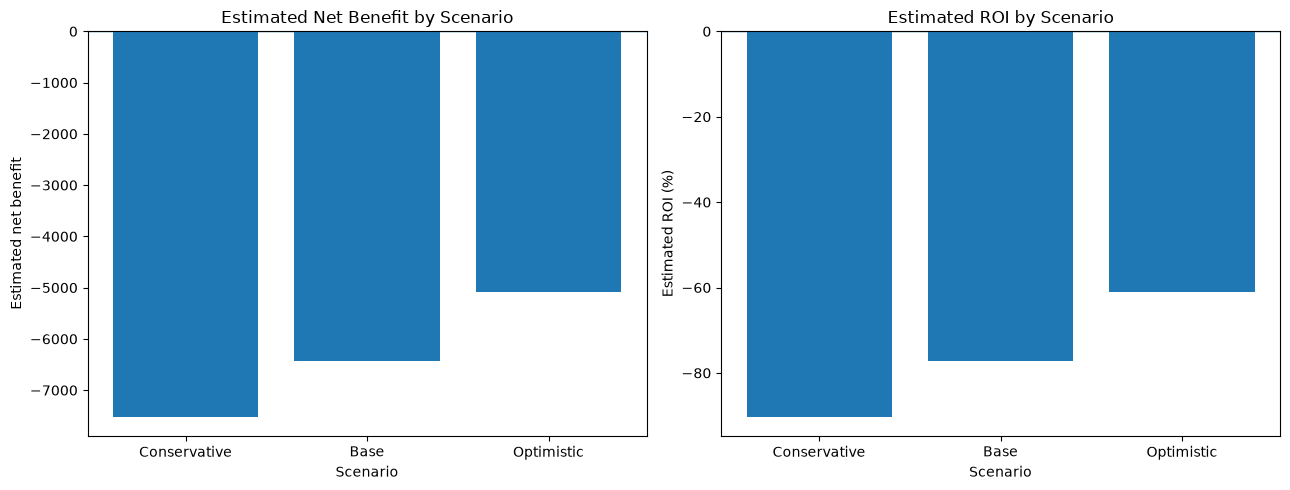

Saved plot: ..\reports\roi\retention_campaign_roi_scenarios.png


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    roi_df["scenario"],
    roi_df["estimated_net_benefit"]
)
axes[0].axhline(0, linewidth=1)
axes[0].set_title("Estimated Net Benefit by Scenario")
axes[0].set_ylabel("Estimated net benefit")
axes[0].set_xlabel("Scenario")

axes[1].bar(
    roi_df["scenario"],
    roi_df["estimated_roi_pct"]
)
axes[1].axhline(0, linewidth=1)
axes[1].set_title("Estimated ROI by Scenario")
axes[1].set_ylabel("Estimated ROI (%)")
axes[1].set_xlabel("Scenario")

plt.tight_layout()

plot_path = output_dir / "retention_campaign_roi_scenarios.png"
plt.savefig("retention_campaign_roi_scenarios.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved plot:", plot_path)

### Create a customer-level campaign shortlist

In [23]:
campaign_shortlist = target_df[
    [retention_id, risk_col, clv_col]
].copy()

campaign_shortlist = campaign_shortlist.rename(columns={
    retention_id: "customer_id",
    risk_col: "predicted_churn_probability",
    clv_col: "estimated_base_clv"
})

campaign_shortlist["assumed_contact_cost"] = COST_PER_CONTACT

campaign_shortlist = campaign_shortlist.sort_values(
    by=["predicted_churn_probability", "estimated_base_clv"],
    ascending=[False, False]
)

shortlist_path = output_dir / "retention_campaign_shortlist.csv"
campaign_shortlist.to_csv(shortlist_path, index=False)

print("Saved shortlist:", shortlist_path)
campaign_shortlist.head(10)

Saved shortlist: ..\reports\roi\retention_campaign_shortlist.csv


,customer_id,predicted_churn_probability,estimated_base_clv,assumed_contact_cost
6,7903-CMPEY,0.905174,26.322856,10.0
9,5494-HECPR,0.905174,26.306465,10.0
11,0137-OCGAB,0.905174,26.290075,10.0
8,6086-ESGRL,0.905174,26.273685,10.0
5,8821-XNHVZ,0.905174,26.240904,10.0
1,1448-PWKYE,0.905174,26.224514,10.0
4,9300-RENDD,0.905174,26.208123,10.0
13,1285-OKIPP,0.905174,26.191733,10.0
15,0495-RVCBF,0.905174,26.126172,10.0
14,8058-INTPH,0.905174,26.109781,10.0


### Save the ROI scenario report

In [24]:
scenario_path = output_dir / "retention_roi_scenarios.csv"
roi_df.to_csv(scenario_path, index=False)

break_even_path = output_dir / "retention_roi_break_even.json"
with open(break_even_path, "w", encoding="utf-8") as file:
    json.dump(break_even_summary, file, indent=4)

summary_path = output_dir / "retention_roi_summary.json"

summary = {
    "analysis": "Scenario-based retention campaign ROI",
    "valid_customer_count": int(total_customers),
    "target_customer_count": int(target_customers),
    "high_risk_threshold": HIGH_RISK_THRESHOLD,
    "cost_per_contact": COST_PER_CONTACT,
    "average_target_clv": float(average_target_clv),
    "campaign_cost": float(campaign_cost),
    "retention_lift_assumptions": RETENTION_LIFT_SCENARIOS,
    "break_even_retention_lift": break_even_summary[
        "break_even_retention_lift"
    ],
    "causal_uplift_validated": False,
    "limitations": [
        "Retention lifts are assumptions, not measured treatment effects.",
        "Actual campaign assignments and outcomes are unavailable.",
        "CLV estimates depend on Notebook 08 assumptions.",
        "Benefits may be overstated if CLV is not contribution value.",
        "No uncertainty intervals are estimated."
    ]
}

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)

print("Saved files:")
print("-", scenario_path)
print("-", break_even_path)
print("-", summary_path)

Saved files:
- ..\reports\roi\retention_roi_scenarios.csv
- ..\reports\roi\retention_roi_break_even.json
- ..\reports\roi\retention_roi_summary.json


### Final business summary

In [25]:
print("=" * 60)
print("RETENTION CAMPAIGN ROI — SUMMARY")
print("=" * 60)

print(f"Customers analyzed: {total_customers:,}")
print(f"High-risk customers targeted: {target_customers:,}")
print(f"Estimated campaign cost: {campaign_cost:,.2f}")
print(f"Average target customer CLV: {average_target_clv:,.2f}")

print("\nScenario comparison:")
display_cols = [
    "scenario",
    "retention_lift_assumption",
    "expected_additional_retained",
    "estimated_campaign_benefit",
    "estimated_net_benefit",
    "estimated_roi_pct"
]

print(roi_df[display_cols].round(2).to_string(index=False))

print("\nImportant:")
print(
    "These are assumption-based financial scenarios, not "
    "validated causal campaign results."
)

RETENTION CAMPAIGN ROI — SUMMARY
Customers analyzed: 7,043
High-risk customers targeted: 833
Estimated campaign cost: 8,330.00
Average target customer CLV: 32.45

Scenario comparison:
    scenario  retention_lift_assumption  expected_additional_retained  estimated_campaign_benefit  estimated_net_benefit  estimated_roi_pct
Conservative                       0.03                         24.99                      811.03               -7518.97             -90.26
        Base                       0.07                         58.31                     1892.41               -6437.59             -77.28
  Optimistic                       0.12                         99.96                     3244.13               -5085.87             -61.05

Important:
These are assumption-based financial scenarios, not validated causal campaign results.
